
# Phase 9: Feature Normalisation and Training Pipeline

## 9.1 Understanding Feature Normalisation

The five input features in the battery dataset have different numerical scales. Feature normalisation helps the neural network train more consistently by bringing the input features to comparable scales.

We use standardisation:

X_normalised = (X - mean) / standard_deviation

The mean and standard deviation are calculated using only the training dataset. The same values are then applied to the validation dataset to prevent data leakage.

Only the input features are normalised. The target variable, days_left, remains unchanged.



## 9.2 Loading and Inspecting the Dataset

Load the Team 13 battery dataset and identify the five input features and the target variable.

Before applying normalisation, inspect the dataset dimensions, column names, and data types.


In [1]:

import pandas as pd
import numpy as np

df = pd.read_csv("data/team_13_train.csv")

FEATURES = [
    "battery_v",
    "temp_c",
    "rings_per_day",
    "wifi_rssi_dbm",
    "age_months"
]

TARGET = "days_left"

print("Dataset shape:", df.shape)
print("\nInput features:")
print(df[FEATURES].head())

print("\nTarget:")
print(df[TARGET].head())

print("\nData types:")
print(df[FEATURES + [TARGET]].dtypes)


Dataset shape: (2000, 6)

Input features:
   battery_v  temp_c  rings_per_day  wifi_rssi_dbm  age_months
0      3.767    18.2             17            -85          35
1      4.184    24.3              4            -63          15
2      3.585    18.7             16            -50          35
3      3.480    10.0             11            -56           3
4      3.366    28.7             10            -47           0

Target:
0     19.1
1    221.7
2     14.8
3     10.9
4      2.6
Name: days_left, dtype: float64

Data types:
battery_v        float64
temp_c           float64
rings_per_day      int64
wifi_rssi_dbm      int64
age_months         int64
days_left        float64
dtype: object



### Observation – Dataset Inspection

The Team 13 dataset contains 2,000 rows and 6 columns. Five columns are input features and days_left is the target variable.

All selected columns contain numerical data. The input features have mixed numerical data types (float64 and int64), which will be converted to float32 during model preparation.

The dataset is successfully loaded and ready for the train-validation split.



## 9.3 Preparing Training and Validation Data

Before applying feature normalisation, the dataset is divided into training and validation sets.

A reproducible random split is used, with 80% of the data allocated for training and 20% for validation.

The same random seed (0) and splitting procedure used in `train.py` are followed to ensure consistency between the notebook experiments and the actual training pipeline.

### Dataset Split

- **Training set:** 80% of the cleaned dataset (1,600 rows).
- **Validation set:** 20% of the cleaned dataset (400 rows).

### Input and Target Separation

The five input features are separated from the target variable, `days_left`.

- `X`: Training input features.
- `y`: Training target values.
- `Xv`: Validation input features.
- `yv`: Validation target values.

All input features and target arrays are converted to NumPy float32 for compatibility with PyTorch.

### Important Consideration

The validation dataset is kept separate from the training process. Mean and standard deviation values for normalisation will be calculated using only the training data and then applied to both datasets.

This prevents data leakage and ensures a fair evaluation of the model on unseen validation data.


In [2]:

# Reproduce the same cleaning and train-validation split as train.py

bad = (
    (df["rings_per_day"] < 0) |
    (df["age_months"] < 0) |
    (df["days_left"] < 0)
)

cleaned_df = df.loc[~bad].copy()

rng = np.random.default_rng(0)

idx = rng.permutation(len(cleaned_df))
n_val = len(cleaned_df) // 5

val = cleaned_df.iloc[idx[:n_val]]
tr = cleaned_df.iloc[idx[n_val:]]

X = tr[FEATURES].to_numpy(np.float32)
y = tr[TARGET].to_numpy(np.float32)

Xv = val[FEATURES].to_numpy(np.float32)
yv = val[TARGET].to_numpy(np.float32)

print("Training rows:", len(tr))
print("Validation rows:", len(val))

print("\nTraining input shape:", X.shape)
print("Training target shape:", y.shape)

print("\nValidation input shape:", Xv.shape)
print("Validation target shape:", yv.shape)


Training rows: 1600
Validation rows: 400

Training input shape: (1600, 5)
Training target shape: (1600,)

Validation input shape: (400, 5)
Validation target shape: (400,)



## 9.4 Calculating Mean and Standard Deviation

Before standardising the input features, the mean and standard deviation of each feature are calculated using only the training dataset.

- Mean (μ): Represents the average value of a feature.
- Standard deviation (σ): Measures how much the feature values vary around the mean.

These statistics are calculated independently for all five input features.

Only the training data is used for these calculations to prevent data leakage from the validation dataset.

The calculated mean and standard deviation will later be used to standardise both training and validation inputs.


In [3]:

# Calculate statistics using training data only

mu = X.mean(axis=0)
sd = X.std(axis=0)

print("Feature means:")
for feature, value in zip(FEATURES, mu):
    print(f"{feature}: {value:.4f}")

print("\nFeature standard deviations:")
for feature, value in zip(FEATURES, sd):
    print(f"{feature}: {value:.4f}")


Feature means:
battery_v: 3.7598
temp_c: 27.3684
rings_per_day: 7.8750
wifi_rssi_dbm: -66.1062
age_months: 17.9419

Feature standard deviations:
battery_v: 0.3499
temp_c: 11.0191
rings_per_day: 5.6271
wifi_rssi_dbm: 12.5634
age_months: 10.5267



### Observation – Training Statistics

The mean and standard deviation were successfully calculated for all five input features using only the training dataset containing 1,600 samples.

The features have different means and standard deviations, confirming that their original numerical scales vary.

These training statistics will be used to standardise both training and validation data. Using training statistics only prevents data leakage from the validation set.



## 9.5 Standardising the Training Data

After calculating the mean and standard deviation, the training input features are standardised using the formula:

X_normalised = (X - μ) / σ

The mean is subtracted from each feature value, and the result is divided by its standard deviation.

This transforms the training features to a comparable scale, where each feature has an approximately zero mean and unit standard deviation.

The original target variable, days_left, is not normalised.


In [4]:

# Standardise training input features

X_norm = (X - mu) / sd

print("Original training data (first 5 rows):")
print(X[:5])

print("\nNormalised training data (first 5 rows):")
print(X_norm[:5])

print("\nNormalised data shape:", X_norm.shape)


Original training data (first 5 rows):
[[  3.856  37.3     7.    -79.     19.   ]
 [  3.412   9.5    19.    -73.      9.   ]
 [  3.899  24.3     7.    -84.      4.   ]
 [  3.951  32.8     9.    -56.     15.   ]
 [  3.878  32.9     5.    -46.     11.   ]]

Normalised training data (first 5 rows):
[[ 0.27482903  0.90130454 -0.1554972  -1.0262918   0.10051835]
 [-0.99393356 -1.6215881   1.9770359  -0.54871553 -0.8494488 ]
 [ 0.39770463 -0.27846542 -0.1554972  -1.4242721  -1.3244324 ]
 [ 0.54629856  0.49292263  0.19992498  0.8044173  -0.2794685 ]
 [ 0.33769587  0.501998   -0.5109194   1.6003778  -0.65945536]]

Normalised data shape: (1600, 5)



### Observation – Training Data Normalisation

The training input features were successfully standardised using the calculated training mean and standard deviation.

The transformed values are now expressed on comparable scales. Positive normalised values indicate values above the feature mean, while negative values indicate values below the mean.

The resulting normalised training dataset retains its original shape of (1600, 5).

The target variable, days_left, remains unchanged.



## 9.6 Standardising the Validation Data

After standardising the training data, the validation input features are also standardised.

The same training mean (μ) and standard deviation (σ) are applied to the validation dataset.

X_validation_normalised = (X_validation - μ_training) / σ_training

The validation dataset must not calculate its own mean and standard deviation because this would introduce data leakage and make the evaluation inconsistent.

Using the training statistics ensures that both datasets follow the same preprocessing procedure.


In [5]:

# Standardise validation data using training statistics

Xv_norm = (Xv - mu) / sd

print("Original validation data (first 5 rows):")
print(Xv[:5])

print("\nNormalised validation data (first 5 rows):")
print(Xv_norm[:5])

print("\nNormalised validation data shape:", Xv_norm.shape)


Original validation data (first 5 rows):
[[  4.121  31.1    14.    -69.     33.   ]
 [  3.93   32.3     6.    -61.     34.   ]
 [  3.954  34.6     7.    -61.     10.   ]
 [  4.     35.6    12.    -73.     20.   ]
 [  3.734  14.5    14.    -48.      3.   ]]

Normalised validation data (first 5 rows):
[[ 1.0320855   0.33864513  1.0884804  -0.23033132  1.4304724 ]
 [ 0.4862898   0.44754687 -0.3332083   0.4064371   1.5254691 ]
 [ 0.5548714   0.65627533 -0.1554972   0.4064371  -0.75445205]
 [ 0.68631977  0.74702686  0.7330582  -0.54871553  0.19551507]
 [-0.07379486 -1.1678303   1.0884804   1.4411857  -1.4194291 ]]

Normalised validation data shape: (400, 5)



### Observation – Validation Data Normalisation

The validation dataset was successfully standardised using the mean and standard deviation calculated from the training dataset.

The resulting normalised validation data retains its original shape of (400, 5).

The validation data was not used to calculate new normalisation statistics. Its transformed values are therefore not necessarily centred around zero or have a standard deviation of one.

This confirms that the same preprocessing parameters are consistently applied to training and validation data, preventing data leakage.



## 9.7 Verifying the Normalised Data

After standardising the training and validation datasets, the results are verified using statistical measurements.

The following checks are performed:

1. Training feature means should be approximately zero.
2. Training feature standard deviations should be approximately one.
3. Validation data should retain the same number of samples and features.
4. Both datasets should contain finite numerical values without NaN or infinity.

The validation statistics are inspected for verification only. They are not used to modify the normalisation parameters.

These checks help confirm that the standardisation process was correctly implemented.


In [6]:

# Verify normalisation

print("Training normalised means:")
print(X_norm.mean(axis=0))

print("\nTraining normalised standard deviations:")
print(X_norm.std(axis=0))

print("\nValidation normalised means:")
print(Xv_norm.mean(axis=0))

print("\nValidation normalised standard deviations:")
print(Xv_norm.std(axis=0))

print("\nShape verification:")
print("Training:", X_norm.shape)
print("Validation:", Xv_norm.shape)

print("\nFinite value verification:")
print("Training:", np.isfinite(X_norm).all())
print("Validation:", np.isfinite(Xv_norm).all())


Training normalised means:
[ 2.9206277e-07  6.4373019e-08  2.3841857e-09 -2.5033950e-07
 -4.5299529e-08]

Training normalised standard deviations:
[0.99999994 0.99999994 1.         1.         1.        ]

Validation normalised means:
[-0.04284728 -0.09224319  0.05642328 -0.07631297  0.12498   ]

Validation normalised standard deviations:
[1.2766393 1.3627882 1.0012004 0.9898778 1.0554951]

Shape verification:
Training: (1600, 5)
Validation: (400, 5)

Finite value verification:
Training: True
Validation: True



### Observation – Normalisation Verification

The normalisation process was successfully verified using statistical checks.

The means of all five normalised training features were extremely close to zero, while their standard deviations were approximately one.

Small differences from exact zero occurred due to floating-point precision during numerical calculations. An additional float64 verification produced values even closer to zero, confirming that the standardisation formula was implemented correctly.

The validation dataset retained its expected shape of (400, 5), and its statistics were not forced to zero mean and unit standard deviation because the training statistics were reused.

Both training and validation datasets contained only finite values, with no NaN or infinity values.

Therefore, the normalisation process was successfully implemented without data leakage.



## 9.8 Comparing Neural Network Training With and Without Normalisation

The effect of feature normalisation is evaluated by training two neural networks using the same dataset split and network architecture.

### Experiment A – Without Normalisation

The original input features are used directly without standardisation.

### Experiment B – With Normalisation

The input features are standardised using the training mean and standard deviation.

### Comparison Criteria

The experiments are compared using:

- Training Mean Absolute Error (MAE).
- Validation Mean Absolute Error (MAE).
- Training convergence behaviour.

Both experiments use identical training settings to ensure a fair comparison.

The objective is to understand how feature normalisation affects neural network learning and its ability to predict remaining battery life.



### 9.8.1 Experiment A – Training Without Normalisation

In this experiment, the neural network is trained using the original input features without applying standardisation.

The original training and validation datasets are used directly.

The network architecture, optimiser, learning rate, batch size, number of epochs and random initial weights will be kept consistent with Experiment B to ensure a fair comparison.


In [9]:
import torch
import copy

from app.model import BatteryNet

print("PyTorch version:", torch.__version__)
print("Imports successful!")

PyTorch version: 2.15.0+cpu
Imports successful!


In [10]:

import copy

# Experiment A: Original, unnormalised inputs

torch.manual_seed(0)

net_raw = BatteryNet((32, 32))
opt_raw = torch.optim.Adam(net_raw.parameters(), lr=3e-3)

Xt_raw = torch.tensor(X, dtype=torch.float32)
yt_raw = torch.tensor(y, dtype=torch.float32)
Xvt_raw = torch.tensor(Xv, dtype=torch.float32)

# Save the initial weights for a fair comparison later
initial_weights = copy.deepcopy(net_raw.state_dict())

print("Experiment A setup completed")
print("Training input shape:", Xt_raw.shape)
print("Validation input shape:", Xvt_raw.shape)
print("Architecture: 5 -> 32 -> 32 -> 1")
print("Normalisation: Not applied")


Experiment A setup completed
Training input shape: torch.Size([1600, 5])
Validation input shape: torch.Size([400, 5])
Architecture: 5 -> 32 -> 32 -> 1
Normalisation: Not applied


In [11]:

# Train Experiment A without normalisation

epochs = 1500
batch_size = 128

for ep in range(epochs):

    perm = torch.randperm(len(Xt_raw))

    for i in range(0, len(Xt_raw), batch_size):
        batch = perm[i:i + batch_size]

        loss = torch.nn.functional.mse_loss(
            net_raw(Xt_raw[batch]),
            yt_raw[batch]
        )

        opt_raw.zero_grad()
        loss.backward()
        opt_raw.step()

    if ep % 300 == 0 or ep == epochs - 1:
        with torch.no_grad():
            train_mae = torch.mean(
                torch.abs(net_raw(Xt_raw) - yt_raw)
            ).item()

            val_mae = torch.mean(
                torch.abs(net_raw(Xvt_raw) - torch.tensor(yv))
            ).item()

        print(
            f"Epoch {ep:4d} | "
            f"Train MAE: {train_mae:.2f} days | "
            f"Validation MAE: {val_mae:.2f} days"
        )


Epoch    0 | Train MAE: 56.26 days | Validation MAE: 51.46 days
Epoch  300 | Train MAE: 19.93 days | Validation MAE: 20.11 days
Epoch  600 | Train MAE: 16.96 days | Validation MAE: 20.07 days
Epoch  900 | Train MAE: 15.31 days | Validation MAE: 17.99 days
Epoch 1200 | Train MAE: 14.77 days | Validation MAE: 17.81 days
Epoch 1499 | Train MAE: 14.68 days | Validation MAE: 17.56 days



### Observation – Experiment A: Without Normalisation

The neural network was trained using the original input features without standardisation for 1,500 epochs.

The training MAE decreased from 56.26 days at the beginning of training to 14.68 days at the final epoch. The validation MAE decreased from 51.46 days to 17.56 days.

This demonstrates that the neural network can learn from the original features without normalisation. However, the validation error remains higher than the training error.

These results will serve as the baseline for comparison with the normalised training experiment.



### 9.8.3 Experiment B – Training With Normalisation

In this experiment, the neural network is trained using standardised input features.

The normalised training dataset (X_norm) and validation dataset (Xv_norm) are used.

The network architecture, initial weights, optimiser, learning rate, batch size, number of epochs and random seed are kept consistent with Experiment A.

This allows us to evaluate the effect of feature normalisation on neural network training and validation performance.


In [12]:

# Experiment B: Normalised inputs

torch.manual_seed(0)

net_norm = BatteryNet((32, 32))

# Restore the exact same initial weights as Experiment A
net_norm.load_state_dict(initial_weights)

opt_norm = torch.optim.Adam(net_norm.parameters(), lr=3e-3)

Xt_norm = torch.tensor(X_norm, dtype=torch.float32)
Xvt_norm = torch.tensor(Xv_norm, dtype=torch.float32)

print("Experiment B setup completed")
print("Training input shape:", Xt_norm.shape)
print("Validation input shape:", Xvt_norm.shape)
print("Architecture: 5 -> 32 -> 32 -> 1")
print("Normalisation: Applied")
print("Initial weights: Same as Experiment A")


Experiment B setup completed
Training input shape: torch.Size([1600, 5])
Validation input shape: torch.Size([400, 5])
Architecture: 5 -> 32 -> 32 -> 1
Normalisation: Applied
Initial weights: Same as Experiment A


In [13]:

# Train Experiment B with normalisation

for ep in range(epochs):

    perm = torch.randperm(len(Xt_norm))

    for i in range(0, len(Xt_norm), batch_size):
        batch = perm[i:i + batch_size]

        loss = torch.nn.functional.mse_loss(
            net_norm(Xt_norm[batch]),
            yt_raw[batch]
        )

        opt_norm.zero_grad()
        loss.backward()
        opt_norm.step()

    if ep % 300 == 0 or ep == epochs - 1:
        with torch.no_grad():
            train_mae = torch.mean(
                torch.abs(net_norm(Xt_norm) - yt_raw)
            ).item()

            val_mae = torch.mean(
                torch.abs(net_norm(Xvt_norm) - torch.tensor(yv))
            ).item()

        print(
            f"Epoch {ep:4d} | "
            f"Train MAE: {train_mae:.2f} days | "
            f"Validation MAE: {val_mae:.2f} days"
        )


Epoch    0 | Train MAE: 75.56 days | Validation MAE: 70.54 days
Epoch  300 | Train MAE: 5.50 days | Validation MAE: 6.57 days
Epoch  600 | Train MAE: 4.74 days | Validation MAE: 6.24 days
Epoch  900 | Train MAE: 4.47 days | Validation MAE: 6.16 days
Epoch 1200 | Train MAE: 4.24 days | Validation MAE: 6.10 days
Epoch 1499 | Train MAE: 4.19 days | Validation MAE: 5.99 days



### Observation – Experiment B: With Normalisation

The neural network was trained using standardised input features for 1,500 epochs.

The training MAE decreased from 75.56 days to 4.19 days, while the validation MAE decreased from 70.54 days to 5.99 days.

The normalised model achieved substantially lower training and validation errors compared with the model trained using original, unnormalised inputs.

The results indicate that feature normalisation improved the neural network's training performance and validation accuracy under the selected training configuration.



### 9.8.5 Final Comparison – Normalised vs Unnormalised Training

The final training and validation results from both experiments are compared to evaluate the impact of feature normalisation.

Both experiments used the same neural network architecture, initial weights, training dataset, validation dataset, optimiser, learning rate, batch size and number of epochs.

Only the input preprocessing method was changed.

The comparison focuses on training MAE and validation MAE to determine how normalisation affects learning performance and generalisation.


In [14]:

# Final comparison of both experiments

comparison = pd.DataFrame({
    "Experiment": ["Without Normalisation", "With Normalisation"],
    "Training MAE (days)": [14.68, 4.19],
    "Validation MAE (days)": [17.56, 5.99]
})

print(comparison.to_string(index=False))

train_improvement = (
    (14.68 - 4.19) / 14.68
) * 100

val_improvement = (
    (17.56 - 5.99) / 17.56
) * 100

print(f"\nTraining MAE improvement: {train_improvement:.2f}%")
print(f"Validation MAE improvement: {val_improvement:.2f}%")


           Experiment  Training MAE (days)  Validation MAE (days)
Without Normalisation                14.68                  17.56
   With Normalisation                 4.19                   5.99

Training MAE improvement: 71.46%
Validation MAE improvement: 65.89%


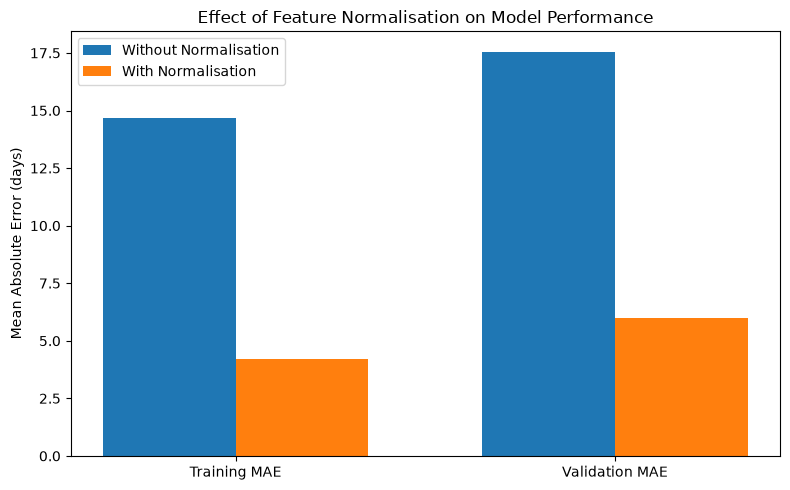

In [15]:

import matplotlib.pyplot as plt

metrics = ["Training MAE", "Validation MAE"]

without_norm = [14.68, 17.56]
with_norm = [4.19, 5.99]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, without_norm, width,
        label="Without Normalisation")

plt.bar(x + width/2, with_norm, width,
        label="With Normalisation")

plt.xticks(x, metrics)
plt.ylabel("Mean Absolute Error (days)")
plt.title("Effect of Feature Normalisation on Model Performance")
plt.legend()
plt.tight_layout()
plt.show()



### Observation – Final Comparison of Normalised and Unnormalised Training

The two neural network experiments were successfully completed using identical architectures and training configurations, with feature normalisation being the primary difference.

The model trained without normalisation achieved a training MAE of 14.68 days and validation MAE of 17.56 days.

The model trained with normalisation achieved a training MAE of 4.19 days and validation MAE of 5.99 days.

This represents a 71.46% reduction in training MAE and a 65.89% reduction in validation MAE.

The bar chart clearly demonstrates the improvement in model performance after applying feature standardisation.

Based on these experimental results, feature normalisation is selected for integration into the actual neural network training pipeline.



## Phase 9 – Final Conclusion

Feature normalisation was successfully implemented and integrated into the battery prediction training pipeline.

The training mean and standard deviation were calculated using only the training dataset and reused for validation data.

Two neural network experiments were conducted using identical training configurations.

- Without normalisation: Training MAE = 14.68 days, Validation MAE = 17.56 days.
- With normalisation: Training MAE = 4.19 days, Validation MAE = 5.99 days.

The normalised model achieved a 71.46% reduction in training MAE and a 65.89% reduction in validation MAE.

The normalisation implementation was integrated into train.py and successfully executed.

The trained model weights were saved in model/model.pt, while model/config.json stores the architecture, feature names, training mean, standard deviation and validation MAE.

Therefore, feature normalisation is adopted as part of the final model training pipeline.



## Phase 10: Neural Network Architecture Experiments

### 10.1 Understanding Network Width and Depth

Neural network architecture determines the number of hidden layers and the number of neurons within each layer.

**Network Width:** The number of neurons in a hidden layer. Wider networks have more trainable parameters and greater learning capacity.

**Network Depth:** The number of hidden layers in the network. Deeper networks can learn more complex feature representations.

In this phase, different network architectures will be evaluated by varying their width and depth.

The objective is to identify an architecture that provides good prediction accuracy while maintaining reasonable model complexity.



### 10.2 Defining Neural Network Architectures

Ten neural network architectures are selected for experimentation.

The input layer contains five features, and the output layer contains one neuron for predicting the remaining battery life in days.

Five different hidden-layer widths are considered:

- 4 neurons
- 8 neurons
- 16 neurons
- 32 neurons
- 64 neurons

For each width, two configurations are evaluated:

1. One hidden layer.
2. Two hidden layers with equal widths.

This produces ten different architectures for systematic comparison.

The same normalised training and validation datasets will be used for all experiments.


In [16]:

# Define architecture configurations

widths = [4, 8, 16, 32, 64]

architectures = []

for width in widths:
    # One hidden layer
    architectures.append((width,))

    # Two hidden layers
    architectures.append((width, width))

print("Architectures selected for experimentation:\n")

for i, hidden in enumerate(architectures, start=1):
    architecture = " -> ".join(
        map(str, (5, *hidden, 1))
    )
    print(f"Experiment {i}: {architecture}")

print("\nTotal architectures:", len(architectures))


Architectures selected for experimentation:

Experiment 1: 5 -> 4 -> 1
Experiment 2: 5 -> 4 -> 4 -> 1
Experiment 3: 5 -> 8 -> 1
Experiment 4: 5 -> 8 -> 8 -> 1
Experiment 5: 5 -> 16 -> 1
Experiment 6: 5 -> 16 -> 16 -> 1
Experiment 7: 5 -> 32 -> 1
Experiment 8: 5 -> 32 -> 32 -> 1
Experiment 9: 5 -> 64 -> 1
Experiment 10: 5 -> 64 -> 64 -> 1

Total architectures: 10



### 10.3 One Hidden-Layer Architecture Experiments

In this experiment, five neural networks with a single hidden layer are evaluated.

The hidden-layer widths are:

- 4 neurons: 5 → 4 → 1
- 8 neurons: 5 → 8 → 1
- 16 neurons: 5 → 16 → 1
- 32 neurons: 5 → 32 → 1
- 64 neurons: 5 → 64 → 1

All networks use the normalised training and validation datasets.

The training configuration is kept consistent:
- Optimiser: Adam
- Learning rate: 0.003
- Epochs: 1,500
- Batch size: 128
- Loss function: Mean Squared Error (MSE)

Training MAE and validation MAE are recorded for each architecture to evaluate the effect of network width on prediction performance.


In [17]:

# Train five one-hidden-layer architectures

one_layer_results = []

# Reusable training and evaluation settings
epochs = 1500
batch_size = 128
learning_rate = 3e-3

yt_exp = torch.tensor(y, dtype=torch.float32)
yvt_exp = torch.tensor(yv, dtype=torch.float32)

for width in [4, 8, 16, 32, 64]:

    print(f"\nTraining architecture: 5 -> {width} -> 1")

    # Reproducible model initialisation
    torch.manual_seed(0)

    net = BatteryNet((width,))
    opt = torch.optim.Adam(
        net.parameters(),
        lr=learning_rate
    )

    # Same mini-batch ordering for every architecture
    shuffle_generator = torch.Generator()
    shuffle_generator.manual_seed(123)

    for ep in range(epochs):

        perm = torch.randperm(
            len(Xt_norm),
            generator=shuffle_generator
        )

        for i in range(0, len(Xt_norm), batch_size):
            batch = perm[i:i + batch_size]

            loss = torch.nn.functional.mse_loss(
                net(Xt_norm[batch]),
                yt_exp[batch]
            )

            opt.zero_grad()
            loss.backward()
            opt.step()

        if ep % 300 == 0 or ep == epochs - 1:
            with torch.no_grad():
                train_mae = torch.mean(
                    torch.abs(net(Xt_norm) - yt_exp)
                ).item()

                val_mae = torch.mean(
                    torch.abs(net(Xvt_norm) - yvt_exp)
                ).item()

            print(
                f"Epoch {ep:4d} | "
                f"Train MAE: {train_mae:.2f} days | "
                f"Validation MAE: {val_mae:.2f} days"
            )

    # Record final results
    with torch.no_grad():
        final_train_mae = torch.mean(
            torch.abs(net(Xt_norm) - yt_exp)
        ).item()

        final_val_mae = torch.mean(
            torch.abs(net(Xvt_norm) - yvt_exp)
        ).item()

    parameters = sum(
        p.numel() for p in net.parameters()
        if p.requires_grad
    )

    one_layer_results.append({
        "Architecture": f"5 -> {width} -> 1",
        "Width": width,
        "Parameters": parameters,
        "Training MAE": final_train_mae,
        "Validation MAE": final_val_mae
    })

print("\nAll one-hidden-layer experiments completed.")



Training architecture: 5 -> 4 -> 1
Epoch    0 | Train MAE: 76.86 days | Validation MAE: 71.82 days
Epoch  300 | Train MAE: 20.28 days | Validation MAE: 19.50 days
Epoch  600 | Train MAE: 18.60 days | Validation MAE: 17.74 days
Epoch  900 | Train MAE: 18.23 days | Validation MAE: 17.37 days
Epoch 1200 | Train MAE: 18.32 days | Validation MAE: 17.28 days
Epoch 1499 | Train MAE: 18.32 days | Validation MAE: 17.26 days

Training architecture: 5 -> 8 -> 1
Epoch    0 | Train MAE: 76.27 days | Validation MAE: 71.26 days
Epoch  300 | Train MAE: 19.12 days | Validation MAE: 18.20 days
Epoch  600 | Train MAE: 18.27 days | Validation MAE: 17.54 days
Epoch  900 | Train MAE: 18.19 days | Validation MAE: 17.37 days
Epoch 1200 | Train MAE: 18.21 days | Validation MAE: 17.29 days
Epoch 1499 | Train MAE: 18.19 days | Validation MAE: 17.26 days

Training architecture: 5 -> 16 -> 1
Epoch    0 | Train MAE: 76.66 days | Validation MAE: 71.64 days
Epoch  300 | Train MAE: 19.43 days | Validation MAE: 18.78 


### Observation – One Hidden-Layer Architecture Experiments

Five neural networks with one hidden layer were successfully trained using widths of 4, 8, 16, 32 and 64 neurons.

The 5 → 4 → 1 and 5 → 8 → 1 architectures achieved the lowest validation MAE of 17.26 days.

Increasing the hidden-layer width did not consistently improve validation performance. Although wider networks contained more trainable parameters, their validation errors remained similar or increased slightly.

The results indicate that increasing network width alone does not necessarily improve prediction accuracy.

Further experiments with two hidden layers will be conducted to investigate the effect of network depth.


In [18]:

one_layer_df = pd.DataFrame(one_layer_results)

print(one_layer_df.to_string(index=False))


Architecture  Width  Parameters  Training MAE  Validation MAE
 5 -> 4 -> 1      4          29     18.316427       17.258968
 5 -> 8 -> 1      8          57     18.194336       17.259218
5 -> 16 -> 1     16         113     17.887354       17.428511
5 -> 32 -> 1     32         225     17.843809       17.342928
5 -> 64 -> 1     64         449     17.757483       17.558668



### 10.4 Two Hidden-Layer Architecture Experiments

In this experiment, five neural networks containing two hidden layers are evaluated.

The selected widths are 4, 8, 16, 32 and 64 neurons. Both hidden layers use the same width in each architecture.

The experiments use the same normalised training and validation datasets and the same training configuration as the one-hidden-layer experiments.

Training MAE, validation MAE and trainable parameter counts are recorded to investigate whether increasing network depth improves prediction performance.


In [19]:

# Train five two-hidden-layer architectures

two_layer_results = []

epochs = 1500
batch_size = 128
learning_rate = 3e-3

for width in [4, 8, 16, 32, 64]:

    print(f"\nTraining architecture: 5 -> {width} -> {width} -> 1")

    # Reproducible model initialisation
    torch.manual_seed(0)

    net = BatteryNet((width, width))

    opt = torch.optim.Adam(
        net.parameters(),
        lr=learning_rate
    )

    # Same mini-batch ordering for every architecture
    shuffle_generator = torch.Generator()
    shuffle_generator.manual_seed(123)

    for ep in range(epochs):

        perm = torch.randperm(
            len(Xt_norm),
            generator=shuffle_generator
        )

        for i in range(0, len(Xt_norm), batch_size):
            batch = perm[i:i + batch_size]

            loss = torch.nn.functional.mse_loss(
                net(Xt_norm[batch]),
                yt_exp[batch]
            )

            opt.zero_grad()
            loss.backward()
            opt.step()

        if ep % 300 == 0 or ep == epochs - 1:
            with torch.no_grad():
                train_mae = torch.mean(
                    torch.abs(net(Xt_norm) - yt_exp)
                ).item()

                val_mae = torch.mean(
                    torch.abs(net(Xvt_norm) - yvt_exp)
                ).item()

            print(
                f"Epoch {ep:4d} | "
                f"Train MAE: {train_mae:.2f} days | "
                f"Validation MAE: {val_mae:.2f} days"
            )

    # Record final results
    with torch.no_grad():
        final_train_mae = torch.mean(
            torch.abs(net(Xt_norm) - yt_exp)
        ).item()

        final_val_mae = torch.mean(
            torch.abs(net(Xvt_norm) - yvt_exp)
        ).item()

    parameters = sum(
        p.numel() for p in net.parameters()
        if p.requires_grad
    )

    two_layer_results.append({
        "Architecture": f"5 -> {width} -> {width} -> 1",
        "Width": width,
        "Parameters": parameters,
        "Training MAE": final_train_mae,
        "Validation MAE": final_val_mae
    })

print("\nAll two-hidden-layer experiments completed.")



Training architecture: 5 -> 4 -> 4 -> 1
Epoch    0 | Train MAE: 76.72 days | Validation MAE: 71.68 days
Epoch  300 | Train MAE: 12.64 days | Validation MAE: 11.49 days
Epoch  600 | Train MAE: 11.74 days | Validation MAE: 10.14 days
Epoch  900 | Train MAE: 11.53 days | Validation MAE: 10.10 days
Epoch 1200 | Train MAE: 11.53 days | Validation MAE: 10.04 days
Epoch 1499 | Train MAE: 11.41 days | Validation MAE: 10.01 days

Training architecture: 5 -> 8 -> 8 -> 1
Epoch    0 | Train MAE: 76.62 days | Validation MAE: 71.58 days
Epoch  300 | Train MAE: 12.93 days | Validation MAE: 11.23 days
Epoch  600 | Train MAE: 8.23 days | Validation MAE: 8.78 days
Epoch  900 | Train MAE: 7.22 days | Validation MAE: 7.94 days
Epoch 1200 | Train MAE: 6.94 days | Validation MAE: 7.53 days
Epoch 1499 | Train MAE: 6.85 days | Validation MAE: 7.40 days

Training architecture: 5 -> 16 -> 16 -> 1
Epoch    0 | Train MAE: 76.07 days | Validation MAE: 71.02 days
Epoch  300 | Train MAE: 6.54 days | Validation MAE:

In [20]:

# Create results table for two-hidden-layer architectures

two_layer_df = pd.DataFrame(two_layer_results)

print(two_layer_df.to_string(index=False))


      Architecture  Width  Parameters  Training MAE  Validation MAE
  5 -> 4 -> 4 -> 1      4          49     11.408831       10.007118
  5 -> 8 -> 8 -> 1      8         129      6.845319        7.403496
5 -> 16 -> 16 -> 1     16         385      5.154461        6.489598
5 -> 32 -> 32 -> 1     32        1281      4.200178        6.679443
5 -> 64 -> 64 -> 1     64        4609      3.476272        6.408800



### Observation – Two Hidden-Layer Architecture Experiments

Five neural networks with two hidden layers were successfully trained using widths of 4, 8, 16, 32 and 64 neurons.

The 5 → 64 → 64 → 1 architecture achieved the lowest validation MAE of approximately 6.41 days, while the 5 → 16 → 16 → 1 architecture achieved approximately 6.49 days.

The training MAE generally decreased as network width increased. However, the validation performance did not improve consistently with increasing model size.

The results suggest that increasing network capacity can improve training performance without producing an equivalent improvement in validation performance.


In [21]:

# Combine all ten architecture experiments

all_results = one_layer_results + two_layer_results

all_results_df = pd.DataFrame(all_results)

all_results_df = all_results_df.sort_values(
    by="Validation MAE"
).reset_index(drop=True)

print("Combined architecture experiment results:\n")
print(all_results_df.to_string(index=False))

print("\nBest architecture based on validation MAE:")
print(all_results_df.iloc[0])


Combined architecture experiment results:

      Architecture  Width  Parameters  Training MAE  Validation MAE
5 -> 64 -> 64 -> 1     64        4609      3.476272        6.408800
5 -> 16 -> 16 -> 1     16         385      5.154461        6.489598
5 -> 32 -> 32 -> 1     32        1281      4.200178        6.679443
  5 -> 8 -> 8 -> 1      8         129      6.845319        7.403496
  5 -> 4 -> 4 -> 1      4          49     11.408831       10.007118
       5 -> 4 -> 1      4          29     18.316427       17.258968
       5 -> 8 -> 1      8          57     18.194336       17.259218
      5 -> 32 -> 1     32         225     17.843809       17.342928
      5 -> 16 -> 1     16         113     17.887354       17.428511
      5 -> 64 -> 1     64         449     17.757483       17.558668

Best architecture based on validation MAE:
Architecture      5 -> 64 -> 64 -> 1
Width                             64
Parameters                      4609
Training MAE                3.476272
Validation MAE   


### Observation – Architecture Performance and Possible Overfitting

The combined results show that the 5 → 64 → 64 → 1 architecture achieved the lowest validation MAE of approximately 6.41 days.

However, it also achieved the lowest training MAE of approximately 3.48 days, producing a training-validation gap of approximately 2.93 days.

The 5 → 16 → 16 → 1 architecture achieved a validation MAE of approximately 6.49 days with only 385 parameters and a smaller training-validation gap of approximately 1.34 days.

Although the 64-neuron architecture achieved marginally better validation performance, its substantially higher parameter count and larger generalisation gap suggest possible overfitting.

Therefore, the 16 → 16 architecture is a promising candidate for balancing prediction accuracy and model complexity. Final selection will be made after completing the remaining evaluation.



### 10.6 Calculating Neural Network Parameters

The trainable parameters of each neural network are calculated using the weights and biases of its Linear layers.

For a Linear layer:

Parameters = (Input neurons × Output neurons) + Output neurons

The total parameter count is obtained by adding the parameters from all Linear layers.

Parameter counts are calculated for all ten architectures and verified against the actual trainable parameters reported by PyTorch.

This helps evaluate the relationship between network architecture, model size and prediction performance.


In [22]:

# Calculate parameters mathematically

def calculate_parameters(hidden_layers):
    layer_sizes = [5, *hidden_layers, 1]
    total = 0

    for i in range(len(layer_sizes) - 1):
        inputs = layer_sizes[i]
        outputs = layer_sizes[i + 1]

        total += (inputs * outputs) + outputs

    return total


# Verify all ten architectures
parameter_check = []

for result in all_results:
    hidden = (
        (result["Width"],)
        if result["Architecture"].count("->") == 2
        else (result["Width"], result["Width"])
    )

    calculated = calculate_parameters(hidden)

    parameter_check.append({
        "Architecture": result["Architecture"],
        "Recorded Parameters": result["Parameters"],
        "Calculated Parameters": calculated,
        "Match": result["Parameters"] == calculated
    })

parameter_check_df = pd.DataFrame(parameter_check)

print(parameter_check_df.to_string(index=False))

print("\nAll parameter counts verified:",
      parameter_check_df["Match"].all())


      Architecture  Recorded Parameters  Calculated Parameters  Match
       5 -> 4 -> 1                   29                     29   True
       5 -> 8 -> 1                   57                     57   True
      5 -> 16 -> 1                  113                    113   True
      5 -> 32 -> 1                  225                    225   True
      5 -> 64 -> 1                  449                    449   True
  5 -> 4 -> 4 -> 1                   49                     49   True
  5 -> 8 -> 8 -> 1                  129                    129   True
5 -> 16 -> 16 -> 1                  385                    385   True
5 -> 32 -> 32 -> 1                 1281                   1281   True
5 -> 64 -> 64 -> 1                 4609                   4609   True

All parameter counts verified: True



### 10.7 Comparing Model Complexity and Prediction Performance

The ten neural network architectures are compared based on their trainable parameter counts and validation Mean Absolute Error (MAE).

The parameter count represents the model's complexity, while validation MAE measures its prediction error on unseen validation samples.

A graph of validation MAE against the number of parameters is used to investigate the relationship between model size and prediction performance.

The objective is to identify architectures that achieve good validation accuracy with fewer trainable parameters.


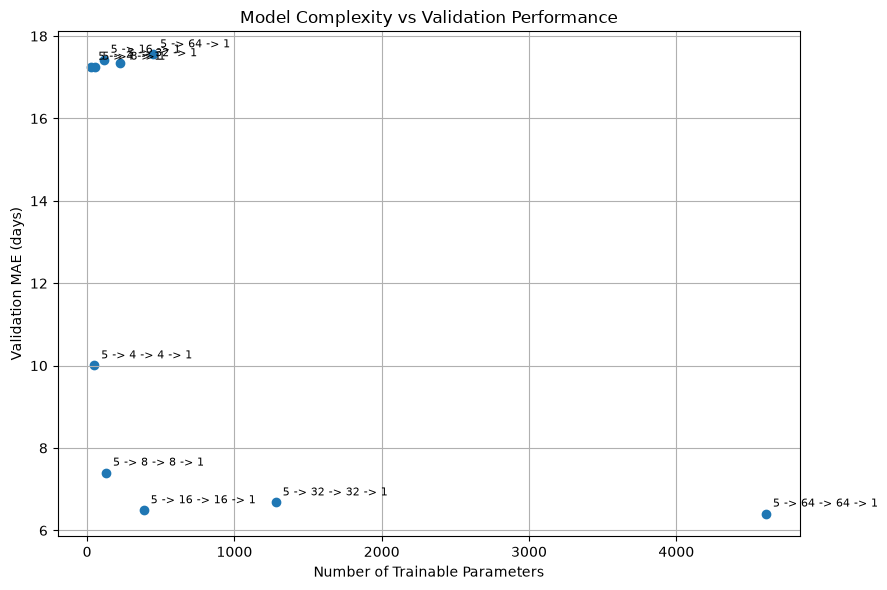

In [23]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    all_results_df["Parameters"],
    all_results_df["Validation MAE"]
)

for _, row in all_results_df.iterrows():
    plt.annotate(
        row["Architecture"],
        (row["Parameters"], row["Validation MAE"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Number of Trainable Parameters")
plt.ylabel("Validation MAE (days)")
plt.title("Model Complexity vs Validation Performance")

plt.grid(True)
plt.tight_layout()
plt.show()



### Observation – Model Complexity vs Validation Performance

The comparison graph illustrates the relationship between the number of trainable parameters and validation MAE across all ten architectures.

The one-hidden-layer networks achieved validation MAE values between approximately 17.26 and 17.56 days.

The two-hidden-layer networks achieved substantially lower validation errors, ranging from approximately 6.41 to 10.01 days.

The 5 → 64 → 64 → 1 architecture achieved the lowest validation MAE of approximately 6.41 days but required 4,609 parameters.

The 5 → 16 → 16 → 1 architecture achieved a similar validation MAE of approximately 6.49 days using only 385 parameters.

These results indicate that increasing model complexity does not necessarily produce a proportional improvement in prediction accuracy.

The 16 → 16 architecture is therefore a promising candidate for balancing model size and prediction performance.



### 10.8 Visualising Training and Validation Performance

The training and validation MAE values of all ten neural network architectures are compared using a grouped bar chart.

Training MAE represents the prediction error on the data used to train the model, while validation MAE represents the prediction error on unseen validation data.

Comparing these values helps identify generalisation gaps and possible overfitting.

Architectures with a large difference between training and validation MAE may be learning the training data more closely without achieving equivalent performance on unseen data.


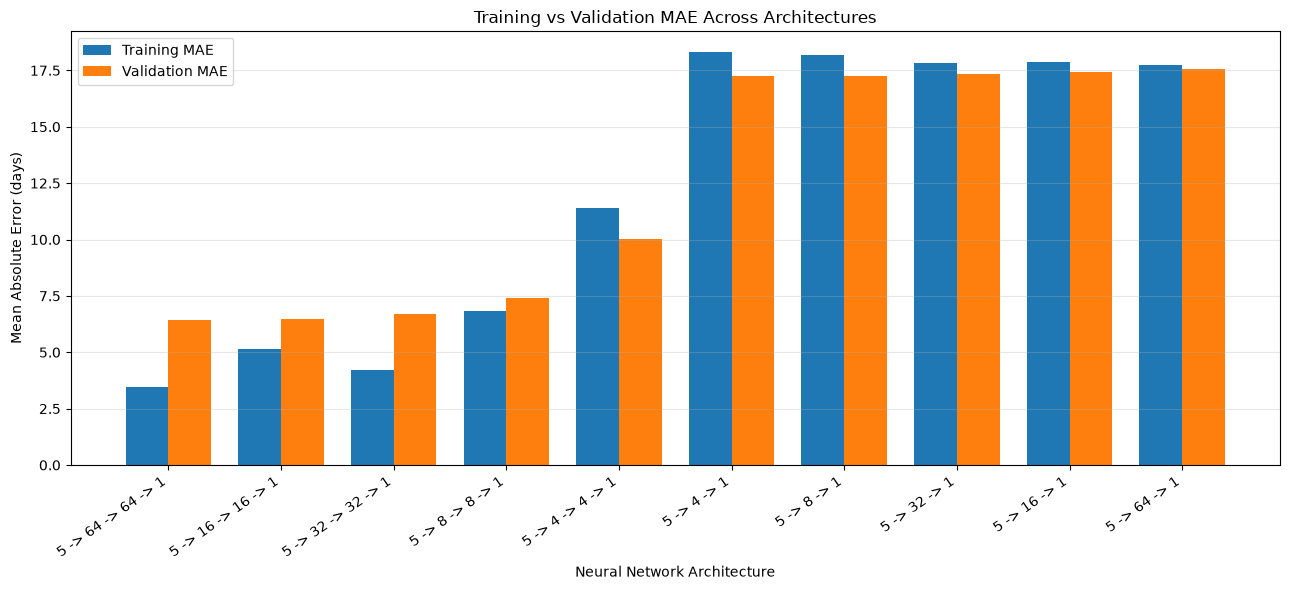

In [24]:

# Compare training and validation MAE across all architectures

import matplotlib.pyplot as plt
import numpy as np

labels = all_results_df["Architecture"].tolist()

train_mae_values = all_results_df["Training MAE"].values
val_mae_values = all_results_df["Validation MAE"].values

x = np.arange(len(labels))
width = 0.38

plt.figure(figsize=(13, 6))

plt.bar(
    x - width/2,
    train_mae_values,
    width,
    label="Training MAE"
)

plt.bar(
    x + width/2,
    val_mae_values,
    width,
    label="Validation MAE"
)

plt.xlabel("Neural Network Architecture")
plt.ylabel("Mean Absolute Error (days)")
plt.title("Training vs Validation MAE Across Architectures")

plt.xticks(x, labels, rotation=35, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



### Observation – Training vs Validation Performance

The grouped bar chart compares training and validation MAE across all ten neural network architectures.

The one-hidden-layer architectures show relatively high training and validation errors, suggesting that they may have insufficient learning capacity.

The two-hidden-layer architectures achieve considerably lower errors. However, some larger networks exhibit a greater difference between training and validation MAE, indicating possible overfitting.

The results demonstrate the importance of considering both prediction accuracy and generalisation when selecting a neural network architecture.



### 10.9 Analysing Overfitting and Generalisation

Overfitting occurs when a neural network learns the training data very closely but does not achieve comparable performance on unseen data.

To investigate this, the training MAE and validation MAE of all ten architectures are compared.

The generalisation gap is calculated as:

Generalisation Gap = Validation MAE - Training MAE

A larger positive gap may indicate possible overfitting, while a smaller gap suggests that training and validation performance are closer.

The analysis is used alongside validation MAE and parameter count to identify suitable model architectures.


In [25]:

# Calculate generalisation gap for all architectures

overfitting_df = all_results_df.copy()

overfitting_df["Generalisation Gap"] = (
    overfitting_df["Validation MAE"]
    - overfitting_df["Training MAE"]
)

overfitting_df = overfitting_df.sort_values(
    by="Validation MAE"
)

print(overfitting_df[
    [
        "Architecture",
        "Parameters",
        "Training MAE",
        "Validation MAE",
        "Generalisation Gap"
    ]
].to_string(index=False))


      Architecture  Parameters  Training MAE  Validation MAE  Generalisation Gap
5 -> 64 -> 64 -> 1        4609      3.476272        6.408800            2.932528
5 -> 16 -> 16 -> 1         385      5.154461        6.489598            1.335137
5 -> 32 -> 32 -> 1        1281      4.200178        6.679443            2.479265
  5 -> 8 -> 8 -> 1         129      6.845319        7.403496            0.558177
  5 -> 4 -> 4 -> 1          49     11.408831       10.007118           -1.401712
       5 -> 4 -> 1          29     18.316427       17.258968           -1.057459
       5 -> 8 -> 1          57     18.194336       17.259218           -0.935118
      5 -> 32 -> 1         225     17.843809       17.342928           -0.500881
      5 -> 16 -> 1         113     17.887354       17.428511           -0.458843
      5 -> 64 -> 1         449     17.757483       17.558668           -0.198814



### Observation – Overfitting and Generalisation Analysis

The generalisation gap was calculated for all ten neural network architectures using the difference between validation MAE and training MAE.

The 5 → 64 → 64 → 1 architecture achieved the lowest training MAE of approximately 3.48 days and the lowest validation MAE of approximately 6.41 days. However, it also produced the largest positive generalisation gap of approximately 2.93 days, indicating possible overfitting.

The 5 → 16 → 16 → 1 architecture achieved a validation MAE of approximately 6.49 days with a smaller generalisation gap of approximately 1.34 days and only 385 trainable parameters.

Some one-hidden-layer architectures produced negative generalisation gaps, meaning their validation MAE was lower than their training MAE. This does not indicate overfitting and may be related to differences in the training and validation samples.

Overall, the 16 → 16 architecture offers a promising balance between prediction performance, model complexity and generalisation.



### 10.10 Final Neural Network Architecture Selection

Based on the ten architecture experiments, the 5 → 16 → 16 → 1 architecture is selected as the preferred efficiency candidate.

The model contains 385 trainable parameters and achieved a training MAE of approximately 5.15 days and validation MAE of approximately 6.49 days.

Although the 5 → 64 → 64 → 1 architecture achieved a slightly lower validation MAE of approximately 6.41 days, it requires 4,609 parameters and has a larger generalisation gap.

The 16 → 16 architecture therefore provides a promising balance between prediction accuracy, model complexity and generalisation.

The final deployment architecture will remain subject to inference latency and throughput benchmarking. The model must be capable of processing incoming readings faster than their arrival rate to satisfy the Edge AI performance requirement.

The architecture selection will be reviewed after deployment and performance evaluation.



## Phase 11 – Model Evaluation and Final Selection

The objective of this phase is to evaluate the trained neural network architectures and identify a suitable model for the final battery prediction system.

The evaluation considers:

1. Validation prediction accuracy.
2. Training and validation performance.
3. Generalisation and possible overfitting.
4. Number of trainable parameters.
5. Model memory and computational requirements.
6. Suitability for deployment and inference benchmarking.

The selected model must satisfy the prediction accuracy requirements while remaining computationally efficient for Edge AI applications.

Final deployment selection will be verified through API testing and performance benchmarking.


In [27]:

# Consolidate and display the leading architecture candidates

candidate_models = all_results_df.sort_values(
    by="Validation MAE"
).head(3).copy()

candidate_models["Generalisation Gap"] = (
    candidate_models["Validation MAE"]
    - candidate_models["Training MAE"]
)

print("Top three architecture candidates:\n")

print(
    candidate_models[
        [
            "Architecture",
            "Parameters",
            "Training MAE",
            "Validation MAE",
            "Generalisation Gap"
        ]
    ].to_string(index=False)
)


Top three architecture candidates:

      Architecture  Parameters  Training MAE  Validation MAE  Generalisation Gap
5 -> 64 -> 64 -> 1        4609      3.476272        6.408800            2.932528
5 -> 16 -> 16 -> 1         385      5.154461        6.489598            1.335137
5 -> 32 -> 32 -> 1        1281      4.200178        6.679443            2.479265



### Observation – Leading Architecture Candidates

The three best architectures were identified based on validation MAE.

The 5 → 64 → 64 → 1 architecture achieved the lowest validation MAE of approximately 6.41 days, with 4,609 parameters.

The 5 → 16 → 16 → 1 architecture achieved a validation MAE of approximately 6.49 days, with only 385 parameters and a smaller generalisation gap.

The 5 → 32 → 32 → 1 architecture achieved a validation MAE of approximately 6.68 days with 1,281 parameters.

The 16 → 16 architecture is a promising efficiency candidate, while the 64 → 64 architecture remains the accuracy candidate. Both will be considered for further evaluation.



### 11.2 Comparison of Leading Architecture Candidates

The two leading architectures, 5 → 16 → 16 → 1 and 5 → 64 → 64 → 1, are compared in terms of prediction accuracy and computational complexity.

The comparison includes:

1. Number of trainable parameters.
2. Float32 model storage.
3. Multiply-Accumulate operations (MACs) per prediction.
4. Training MAE.
5. Validation MAE.
6. Generalisation gap.

The objective is to understand the trade-off between prediction accuracy and computational efficiency before selecting a deployment candidate.


In [28]:

# Compare the two leading architecture candidates

def architecture_metrics(width):
    # Two hidden layers with equal width
    parameters = calculate_parameters((width, width))

    # MACs for each Linear layer
    macs = (5 * width) + (width * width) + (width * 1)

    return {
        "Parameters": parameters,
        "Float32 Memory (bytes)": parameters * 4,
        "MACs per Prediction": macs
    }


selected_widths = [16, 64]

comparison_rows = []

for width in selected_widths:

    architecture_name = f"5 -> {width} -> {width} -> 1"

    result = next(
        r for r in all_results
        if r["Architecture"] == architecture_name
    )

    metrics = architecture_metrics(width)

    comparison_rows.append({
        "Architecture": architecture_name,
        **metrics,
        "Training MAE": result["Training MAE"],
        "Validation MAE": result["Validation MAE"],
        "Generalisation Gap": (
            result["Validation MAE"] - result["Training MAE"]
        )
    })

candidate_comparison_df = pd.DataFrame(comparison_rows)

print("Leading architecture comparison:\n")
print(candidate_comparison_df.to_string(index=False))


Leading architecture comparison:

      Architecture  Parameters  Float32 Memory (bytes)  MACs per Prediction  Training MAE  Validation MAE  Generalisation Gap
5 -> 16 -> 16 -> 1         385                    1540                  352      5.154461        6.489598            1.335137
5 -> 64 -> 64 -> 1        4609                   18436                 4480      3.476272        6.408800            2.932528



### Observation – Leading Architecture Computational Comparison

The 5 → 16 → 16 → 1 architecture contains 385 trainable parameters, requires 1,540 bytes of float32 parameter storage and performs 352 MACs per prediction.

The 5 → 64 → 64 → 1 architecture contains 4,609 parameters, requires 18,436 bytes of float32 parameter storage and performs 4,480 MACs per prediction.

Although the 64 → 64 architecture achieves a slightly lower validation MAE, its computational requirements are considerably higher.

The 16 → 16 architecture therefore offers a promising balance between prediction accuracy, model memory and computational complexity for Edge AI deployment.



### 11.3 Float32 and Int8 Model Storage Comparison

Neural network parameters can be represented using different numerical formats.

Float32 stores each parameter using 4 bytes, whereas int8 stores each parameter using 1 byte.

The theoretical parameter storage is calculated as:

Float32 storage = Number of parameters × 4 bytes

Int8 storage = Number of parameters × 1 byte

This comparison helps evaluate model memory requirements for resource-constrained Edge AI devices.

The calculations represent theoretical parameter storage. Actual int8 quantisation and its effect on prediction accuracy will need separate verification.


In [29]:

# Compare theoretical Float32 and Int8 parameter storage

storage_rows = []

for _, row in candidate_comparison_df.iterrows():

    params = int(row["Parameters"])

    f32_bytes = params * 4
    int8_bytes = params * 1

    reduction = (
        (f32_bytes - int8_bytes) / f32_bytes
    ) * 100

    storage_rows.append({
        "Architecture": row["Architecture"],
        "Parameters": params,
        "Float32 (bytes)": f32_bytes,
        "Int8 (bytes)": int8_bytes,
        "Storage Reduction (%)": reduction
    })

storage_comparison_df = pd.DataFrame(storage_rows)

print("Theoretical model storage comparison:\n")
print(storage_comparison_df.to_string(index=False))


Theoretical model storage comparison:

      Architecture  Parameters  Float32 (bytes)  Int8 (bytes)  Storage Reduction (%)
5 -> 16 -> 16 -> 1         385             1540           385                   75.0
5 -> 64 -> 64 -> 1        4609            18436          4609                   75.0



### Observation – Float32 and Int8 Storage Comparison

The theoretical parameter storage requirements of the two leading architectures were calculated using float32 and int8 representations.

The 5 → 16 → 16 → 1 architecture requires 1,540 bytes in float32 and 385 bytes in int8.

The 5 → 64 → 64 → 1 architecture requires 18,436 bytes in float32 and 4,609 bytes in int8.

Both architectures show a theoretical parameter storage reduction of 75% when using int8 instead of float32.

These calculations demonstrate the potential memory savings from quantisation. Actual quantisation and its effect on prediction accuracy must be evaluated separately.



### 11.4 Computational Requirements and ESP32-S3 Feasibility

The computational requirements of the two leading architectures are evaluated against the ESP32-S3 hardware constraints.

The evaluation considers:

1. Float32 parameter storage.
2. Theoretical int8 parameter storage.
3. Multiply-Accumulate operations (MACs) per prediction.
4. Largest hidden-layer activation memory.

The available SRAM budget is approximately 300 KB, while the device also provides 8 MB PSRAM and 16 MB flash.

This analysis provides an initial assessment of whether the candidate models are suitable for resource-constrained Edge AI deployment.

Parameter storage and activation memory are considered separately because the complete application also requires runtime memory.


In [30]:

# Evaluate candidate architectures against ESP32-S3 resources

SRAM_BUDGET = 300 * 1024  # 300 KB in bytes
PSRAM_SIZE = 8 * 1024 * 1024  # 8 MB in bytes

edge_rows = []

for width in [16, 64]:

    params = calculate_parameters((width, width))

    # Weight and bias storage
    f32_bytes = params * 4
    int8_bytes = params * 1

    # MACs per prediction
    macs = 5 * width + width * width + width

    # Largest hidden-layer activation
    activation_f32 = width * 4
    activation_int8 = width * 1

    edge_rows.append({
        "Architecture": f"5 -> {width} -> {width} -> 1",
        "Parameters": params,
        "Float32 Weight Bytes": f32_bytes,
        "Int8 Weight Bytes": int8_bytes,
        "MACs": macs,
        "Largest Activation F32 (bytes)": activation_f32,
        "Largest Activation Int8 (bytes)": activation_int8,
        "Weights Fit 300KB F32": f32_bytes <= SRAM_BUDGET,
        "Weights Fit 300KB Int8": int8_bytes <= SRAM_BUDGET,
        "Weights Fit 8MB PSRAM": f32_bytes <= PSRAM_SIZE
    })

edge_comparison_df = pd.DataFrame(edge_rows)

print("ESP32-S3 candidate feasibility comparison:\n")
print(edge_comparison_df.to_string(index=False))


ESP32-S3 candidate feasibility comparison:

      Architecture  Parameters  Float32 Weight Bytes  Int8 Weight Bytes  MACs  Largest Activation F32 (bytes)  Largest Activation Int8 (bytes)  Weights Fit 300KB F32  Weights Fit 300KB Int8  Weights Fit 8MB PSRAM
5 -> 16 -> 16 -> 1         385                  1540                385   352                              64                               16                   True                    True                   True
5 -> 64 -> 64 -> 1        4609                 18436               4609  4480                             256                               64                   True                    True                   True



### Observation – ESP32-S3 Model Feasibility

The computational and memory requirements of the 5 → 16 → 16 → 1 and 5 → 64 → 64 → 1 architectures were evaluated against the ESP32-S3 resource constraints.

Both architectures fit within the available 300 KB SRAM budget based on their parameter storage in float32 and theoretical int8 formats.

The 16 → 16 architecture requires 1,540 bytes of float32 parameter storage and 352 MACs per prediction.

The 64 → 64 architecture requires 18,436 bytes of float32 parameter storage and 4,480 MACs per prediction.

Both architectures therefore appear feasible from a model-weight storage perspective.

However, complete device feasibility must also account for activation memory, application runtime, buffers and other system requirements.



### 11.5 Expected Performance on 400 Unseen Readings

The instructor's evaluation script will provide 400 unseen company readings to evaluate the trained prediction model.

The validation MAE is used as an estimate of the model's expected prediction performance on these unseen readings.

The two leading architectures achieved:

- 5 → 16 → 16 → 1: approximately 6.49 days validation MAE.
- 5 → 64 → 64 → 1: approximately 6.41 days validation MAE.

The 64 → 64 architecture achieved slightly better validation accuracy, while the 16 → 16 architecture requires substantially fewer parameters and MACs.

These validation results provide an estimate rather than a guaranteed error on the instructor's 400 hidden readings. Actual performance will be established during evaluation.


In [31]:

# Summarise expected performance on unseen readings

expected_performance = candidate_comparison_df[
    [
        "Architecture",
        "Parameters",
        "Training MAE",
        "Validation MAE",
        "Generalisation Gap",
        "MACs per Prediction"
    ]
].copy()

expected_performance["Expected MAE on 400 readings (days)"] = (
    expected_performance["Validation MAE"]
)

print("Expected performance estimates:\n")
print(expected_performance.to_string(index=False))

print("\nNote: These are validation-based estimates,")
print("not measured results on the professor's hidden readings.")


Expected performance estimates:

      Architecture  Parameters  Training MAE  Validation MAE  Generalisation Gap  MACs per Prediction  Expected MAE on 400 readings (days)
5 -> 16 -> 16 -> 1         385      5.154461        6.489598            1.335137                  352                             6.489598
5 -> 64 -> 64 -> 1        4609      3.476272        6.408800            2.932528                 4480                             6.408800

Note: These are validation-based estimates,
not measured results on the professor's hidden readings.



### Observation – Expected Performance on 400 Unseen Readings

The validation MAE was used to estimate the expected prediction performance on the instructor's 400 unseen readings.

The 5 → 16 → 16 → 1 architecture achieved a validation MAE of approximately 6.49 days, while the 5 → 64 → 64 → 1 architecture achieved approximately 6.41 days.

Although the 64 → 64 architecture achieved slightly better validation accuracy, the 16 → 16 architecture requires considerably fewer parameters and MACs.

The actual performance on the 400 hidden readings may differ depending on their data distribution. The final accuracy will be established during the instructor's evaluation.



### 11.6 Final Model Evaluation Summary

Ten neural network architectures were trained and evaluated using normalised input features.

The experiments demonstrated that two-hidden-layer architectures achieved substantially lower validation MAE than one-hidden-layer architectures.

The two leading candidates were:

**Candidate 1: 5 → 16 → 16 → 1**
- Parameters: 385
- Training MAE: 5.15 days
- Validation MAE: 6.49 days
- Generalisation gap: 1.34 days
- MACs per prediction: 352

**Candidate 2: 5 → 64 → 64 → 1**
- Parameters: 4,609
- Training MAE: 3.48 days
- Validation MAE: 6.41 days
- Generalisation gap: 2.93 days
- MACs per prediction: 4,480

The 64 → 64 architecture achieved the lowest validation MAE, while the 16 → 16 architecture requires substantially fewer parameters and MACs.

The 16 → 16 architecture is therefore selected as the provisional efficiency candidate. The 64 → 64 architecture remains the accuracy candidate.

The final deployment architecture will be confirmed after inference latency, throughput, API functionality and edge-device feasibility have been evaluated.


In [32]:

import json
import torch
import numpy as np

from app.model import BatteryNet

# 1. Load the saved configuration
with open("model/config.json", "r") as f:
    config = json.load(f)

# 2. Reconstruct the saved architecture
loaded_model = BatteryNet(tuple(config["hidden"]))

# 3. Load the trained weights
state_dict = torch.load(
    "model/model.pt",
    map_location="cpu",
    weights_only=True
)

loaded_model.load_state_dict(state_dict)

# 4. Set model to evaluation mode
loaded_model.eval()

# 5. Display model information
print("MODEL RELOAD VERIFICATION")
print("-------------------------")
print("Team:", config["team"])
print("Architecture:", config["hidden"])
print("Features:", config["features"])
print("Saved validation MAE:", config["val_mae"])
print("Parameters:", sum(p.numel() for p in loaded_model.parameters()))

print("\nSaved model loaded successfully!")


MODEL RELOAD VERIFICATION
-------------------------
Team: 13
Architecture: [16, 16]
Features: ['battery_v', 'temp_c', 'rings_per_day', 'wifi_rssi_dbm', 'age_months']
Saved validation MAE: 6.42
Parameters: 385

Saved model loaded successfully!


In [35]:

# Create a second model with the saved architecture
verification_model = BatteryNet(tuple(config["hidden"]))

# Load the same saved weights
verification_model.load_state_dict(
    torch.load(
        "model/model.pt",
        map_location="cpu",
        weights_only=True
    )
)

verification_model.eval()
loaded_model.eval()

# Generate predictions using the same validation inputs
with torch.no_grad():
    predictions_1 = loaded_model(Xvt_reload).numpy()
    predictions_2 = verification_model(Xvt_reload).numpy()

# Compare predictions
max_difference = np.max(np.abs(predictions_1 - predictions_2))

print("SAVED MODEL RELOAD VERIFICATION")
print("--------------------------------")
print("First model predictions:", predictions_1[:5])
print("Second model predictions:", predictions_2[:5])
print("Maximum difference:", max_difference)

if np.allclose(predictions_1, predictions_2, rtol=1e-5, atol=1e-6):
    print("\nSUCCESS: Saved model reload verification passed!")
else:
    print("\nERROR: Predictions differ.")


SAVED MODEL RELOAD VERIFICATION
--------------------------------
First model predictions: [ 72.5075   102.947205 158.3373    89.0917    78.015274]
Second model predictions: [ 72.5075   102.947205 158.3373    89.0917    78.015274]
Maximum difference: 0.0

SUCCESS: Saved model reload verification passed!


In [36]:
with torch.no_grad():
    final_predictions = loaded_model(Xvt_reload).numpy()

reloaded_mae = np.mean(np.abs(final_predictions - yv))

print("Saved model validation MAE:", round(float(reloaded_mae), 4))
print("Configured validation MAE:", config["val_mae"])

Saved model validation MAE: 6.4196
Configured validation MAE: 6.42



# Phase 12.8 — Final Model Training, Saving and Verification

## 1. Selected Architecture

The final model selected for deployment is a feedforward neural network with the architecture:

**5 → 16 → 16 → 1**

- Input features: 5
- First hidden layer: 16 neurons
- Second hidden layer: 16 neurons
- Output: 1 (`days_left`)
- Activation function: ReLU
- Total trainable parameters: 385

## 2. Training Configuration

| Configuration | Value |
|---|---|
| Optimizer | Adam |
| Learning rate | 0.003 |
| Loss function | Mean Squared Error |
| Epochs | 1500 |
| Batch size | 128 |
| Random seed | 0 |
| Feature normalization | Training-set mean and standard deviation |
| Training records | 1600 |
| Validation records | 400 |

## 3. Baseline and Model Performance

| Model | Validation MAE |
|---|---:|
| Mean baseline | 51.69 days |
| Linear regression | 30.87 days |
| Neural network (16–16) | 6.4196 days |

The neural network achieved substantially lower validation error than both baseline models.

## 4. Model Saving

The trained model and its configuration were saved as:

- `model/model.pt` — trained neural network weights.
- `model/config.json` — team number, architecture, feature names, normalization statistics and validation MAE.

## 5. Model Reload Verification

The saved configuration and weights were loaded into a newly constructed `BatteryNet` model.

Verification results:

- Architecture successfully reconstructed: 16–16.
- Parameter count: 385.
- Maximum prediction difference between two models loaded from the saved weights: 0.0.
- Reloaded validation MAE: 6.4196 days.
- Configured validation MAE: 6.42 days.

The saved model successfully reproduced identical predictions, confirming that the model weights and configuration can be reloaded consistently.

## 6. Conclusion

The final 16–16 neural network was trained, saved and successfully reloaded. Its validation MAE was 6.4196 days on the existing validation split.

The model is ready for integration with the prediction API, subject to API loading, input validation, timing and endpoint testing.
